코드 13
ViT(Vision Transformer) + EfficientNet ensemble
앙상블 가중치 조절 --> 4감정+4감정 앙상블을 8개의 feature로 간주, lightGBM을 직렬구조로 regression 추가


In [1]:
import os
os.environ['OPENCV_LOG_LEVEL'] = 'ERROR' 

import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import random
import math
import lightgbm as lgb
from sklearn.metrics import accuracy_score

# ================= 설정 =================
RAW_IMG_BASE = "/workspace/user1/dataset_v2/img/train" 
LBL_BASE = "/workspace/user1/dataset_v2/label_mod/train"
VAL_IMG_BASE = "/workspace/user1/dataset_v2/img/val"
VAL_LBL_BASE = "/workspace/user1/dataset_v2/label_mod/val"
AUG_IMG_BASE = "/workspace/user5/img_augmented/train"

SAVE_DIR = '/workspace/user1/model_v8_arcface'
EFF_WEIGHT_PATH = '/workspace/user1/model_v8_arcface/best_stage2_arcface.pth'
VIT_WEIGHT_PATH = os.path.join(SAVE_DIR, 'vit_arcface_sync_best.pth')

SEED = 42
BATCH_SIZE = 64
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

STAGE2_MAP = {'anger': 0, 'happy': 1, 'panic': 2, 'sadness': 3}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print(f"✅ 환경 설정 완료. 장치: {DEVICE}")

✅ 환경 설정 완료. 장치: cuda


In [2]:
# 앙상블 피처 추출 시에는 원본 이미지만 사용하므로 Augmentation을 배제한 전처리 사용 (기준: 260x260)
ens_transform = A.Compose([
    A.Resize(260, 260),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class ArcFaceStage2Dataset(Dataset):
    def __init__(self, raw_img_base, aug_img_base, lbl_base, transform=None, is_train=True):
        self.transform = transform
        self.samples = []
        counts = {0: 0, 1: 0, 2: 0, 3: 0}

        if os.path.exists(lbl_base):
            for json_file in tqdm(os.listdir(lbl_base), desc="Loading JSONs"):
                if not json_file.endswith('.json'): continue
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        if item.get('is_box_issue') == 'Yes': continue
                        emotion = item['final_emotion']
                        if emotion in ['neutral', 'blank']: continue
                        
                        label = STAGE2_MAP[emotion]
                        counts[label] += 1
                        self.samples.append({
                            'source': 'raw',
                            'img_path': os.path.join(raw_img_base, emotion, item['filename']),
                            'bbox': item['bbox'],
                            'label': label
                        })

        if is_train and os.path.exists(aug_img_base):
            for emotion_name in STAGE2_MAP.keys():
                src_folder = os.path.join(aug_img_base, emotion_name)
                if not os.path.isdir(src_folder): continue
                
                label = STAGE2_MAP[emotion_name]
                for filename in os.listdir(src_folder):
                    counts[label] += 1
                    self.samples.append({
                        'source': 'aug',
                        'img_path': os.path.join(src_folder, filename),
                        'label': label
                    })

        print(f"✅ 로딩 완료. {counts}")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        image = cv2.imread(item['img_path'])
        if image is None: return self.__getitem__(random.randint(0, len(self)-1))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        if item['source'] == 'raw':
            box = item['bbox']
            x1, y1, x2, y2 = max(0, box['minX']), max(0, box['minY']), box['maxX'], box['maxY']
            image = image[y1:y2, x1:x2]
            
        if self.transform:
            image = self.transform(image=image)['image']
            
        return image, torch.tensor(item['label'], dtype=torch.long)

# 메타 모델 훈련용(Train)과 검증용(Valid) 로더 생성 
# (Train 추출 시 Augmentation 이미지를 제외하기 위해 is_train=False 설정)
ens_train_dataset = ArcFaceStage2Dataset(RAW_IMG_BASE, AUG_IMG_BASE, LBL_BASE, transform=ens_transform, is_train=False)
ens_val_dataset = ArcFaceStage2Dataset(VAL_IMG_BASE, AUG_IMG_BASE, VAL_LBL_BASE, transform=ens_transform, is_train=False)

ens_train_loader = DataLoader(ens_train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True)
ens_val_loader = DataLoader(ens_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=8, pin_memory=True)

Loading JSONs:   0%|          | 0/5 [00:00<?, ?it/s]

Loading JSONs: 100%|██████████| 5/5 [00:00<00:00, 10.74it/s]


✅ 로딩 완료. {0: 855, 1: 1397, 2: 1510, 3: 1567}


Loading JSONs: 100%|██████████| 5/5 [00:00<00:00, 63.98it/s]

✅ 로딩 완료. {0: 184, 1: 281, 2: 303, 3: 269}


In [3]:
class ArcMarginProduct(nn.Module):
    def __init__(self, in_features, out_features, s=30.0, m=0.50, easy_margin=False):
        super(ArcMarginProduct, self).__init__()
        self.s = s
        self.m = m
        self.weight = nn.Parameter(torch.FloatTensor(out_features, in_features))
        nn.init.xavier_uniform_(self.weight)

        self.easy_margin = easy_margin
        self.cos_m = math.cos(m)
        self.sin_m = math.sin(m)
        self.th = math.cos(math.pi - m)
        self.mm = math.sin(math.pi - m) * m

    def forward(self, input, label=None):
        cosine = F.linear(F.normalize(input), F.normalize(self.weight))
        if label is None:
            return cosine * self.s
            
        sine = torch.sqrt(1.0 - torch.pow(cosine, 2))
        phi = cosine * self.cos_m - sine * self.sin_m
        if self.easy_margin:
            phi = torch.where(cosine > 0, phi, cosine)
        else:
            phi = torch.where(cosine > self.th, phi, cosine - self.mm)
        
        one_hot = torch.zeros(cosine.size(), device=DEVICE)
        one_hot.scatter_(1, label.view(-1, 1).long(), 1)
        
        output = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        output *= self.s
        
        return output, cosine

class EffNetArcFace(nn.Module):
    def __init__(self, num_classes=4):
        super(EffNetArcFace, self).__init__()
        self.backbone = timm.create_model('efficientnet_b2', pretrained=False, num_classes=0)
        self.arcface = ArcMarginProduct(in_features=1408, out_features=num_classes, s=30.0, m=0.7)

    def forward(self, x):
        features = self.backbone(x)
        cosine = F.linear(F.normalize(features), F.normalize(self.arcface.weight))
        return cosine * self.arcface.s

class ViTArcFace(nn.Module):
    def __init__(self, num_classes=4, m=0.5):
        super(ViTArcFace, self).__init__()
        self.backbone = timm.create_model('vit_base_patch16_224', pretrained=False, num_classes=0)
        embed_dim = self.backbone.num_features 
        self.arcface = ArcMarginProduct(in_features=embed_dim, out_features=num_classes, s=30.0, m=m)

    def forward(self, x):
        features = self.backbone(x)
        cosine = F.linear(F.normalize(features), F.normalize(self.arcface.weight))
        return cosine * self.arcface.s

print("모델 구조 생성 및 가중치 로드 중...")
eff_model = EffNetArcFace(num_classes=4).to(DEVICE)
eff_model.load_state_dict(torch.load(EFF_WEIGHT_PATH, map_location=DEVICE))
eff_model.eval()

vit_model = ViTArcFace(num_classes=4, m=0.5).to(DEVICE)
vit_model.load_state_dict(torch.load(VIT_WEIGHT_PATH, map_location=DEVICE))
vit_model.eval()
print("✅ 가중치 로드 완료.")

모델 구조 생성 및 가중치 로드 중...


✅ 가중치 로드 완료.


In [7]:
def extract_tta_logits(loader, desc):
    all_eff_logits = []
    all_vit_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            images_flipped = torch.flip(images, dims=[3])
            
            with torch.amp.autocast('cuda'):
                # EfficientNet TTA
                eff_out_orig = eff_model(images)
                eff_out_flip = eff_model(images_flipped)
                eff_tta_cosine = (eff_out_orig + eff_out_flip) / 2.0
                
                # ViT TTA
                vit_images_orig = F.interpolate(images, size=(224, 224), mode='bilinear', align_corners=False)
                vit_images_flip = F.interpolate(images_flipped, size=(224, 224), mode='bilinear', align_corners=False)
                vit_out_orig = vit_model(vit_images_orig)
                vit_out_flip = vit_model(vit_images_flip)
                vit_tta_cosine = (vit_out_orig + vit_out_flip) / 2.0
                
                all_eff_logits.append(eff_tta_cosine.cpu())
                all_vit_logits.append(vit_tta_cosine.cpu())
                all_labels.append(labels.cpu())

    X_eff = torch.cat(all_eff_logits).numpy()
    X_vit = torch.cat(all_vit_logits).numpy()
    y = torch.cat(all_labels).numpy()
    
    return X_eff, X_vit, y

# Train 데이터 및 Valid 데이터에 대한 특징 추출
X_train_eff, X_train_vit, y_train = extract_tta_logits(ens_train_loader, "[Extracting Train TTA Logits]")
X_val_eff, X_val_vit, y_val = extract_tta_logits(ens_val_loader, "[Extracting Valid TTA Logits]")

[Extracting Train TTA Logits]:   0%|          | 0/84 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
[Extracting Train TTA Logits]:  10%|▉         | 8/84 [00:07<00:23,  3.21it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
[Extracting Train TTA Logits]:  19%|█▉        | 16/84 [00:11<00:16,  4.10it/s]In

In [8]:
# 1. Feature 결합 (EffNet 4차원 + ViT 4차원 = 총 8차원)
X_train_meta = np.hstack((X_train_eff, X_train_vit))
X_val_meta = np.hstack((X_val_eff, X_val_vit))

# 2. LightGBM 데이터셋 생성
lgb_train = lgb.Dataset(X_train_meta, label=y_train)
lgb_val = lgb.Dataset(X_val_meta, label=y_val, reference=lgb_train)

# 3. 모델 파라미터 설정 (과적합 방지 최적화)
params = {
    'objective': 'multiclass',
    'num_class': 4,
    'metric': 'multi_error',
    'boosting_type': 'gbdt',
    'learning_rate': 0.03,
    'max_depth': 3,
    'num_leaves': 7,
    'min_child_samples': 30,
    'feature_fraction': 0.8,
    'seed': 42,
    'verbose': -1
}

print("\nLightGBM 메타 모델 학습을 시작합니다...")

callbacks = [
    lgb.early_stopping(stopping_rounds=50, verbose=False),
    lgb.log_evaluation(period=100)
]

meta_model = lgb.train(
    params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_train, lgb_val],
    valid_names=['train', 'val'],
    callbacks=callbacks
)

# 4. 최종 앙상블 성능 평가
y_pred_prob = meta_model.predict(X_val_meta)
y_pred_class = np.argmax(y_pred_prob, axis=1)

final_acc = accuracy_score(y_val, y_pred_class)
print(f"\n★ [LightGBM Stacking] 최종 앙상블 성능: {final_acc:.4f}")

# 메타 모델 저장
meta_model.save_model(os.path.join(SAVE_DIR, 'lgb_meta_model.txt'))


LightGBM 메타 모델 학습을 시작합니다...



★ [LightGBM Stacking] 최종 앙상블 성능: 0.8582


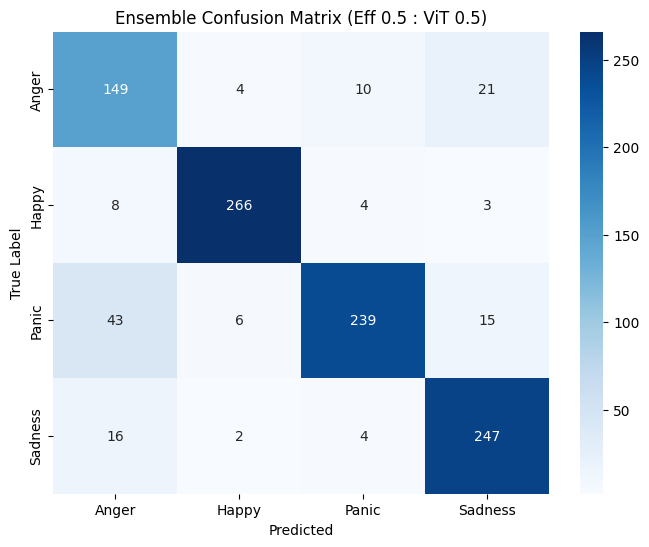


=== 클래스별 예측 성능 상세 보고서 ===
              precision    recall  f1-score   support

       Anger       0.69      0.81      0.74       184
       Happy       0.96      0.95      0.95       281
       Panic       0.93      0.79      0.85       303
     Sadness       0.86      0.92      0.89       269

    accuracy                           0.87      1037
   macro avg       0.86      0.87      0.86      1037
weighted avg       0.88      0.87      0.87      1037



In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. 최고 성능을 냈던 가중치(Eff 0.7 : ViT 0.3)로 최종 예측값 생성
w_eff = 0.5
w_vit = 0.5

# 이전에 추출해둔 Validation TTA Logit 사용 (X_val_eff, X_val_vit)
ensemble_logits = (X_val_eff * w_eff) + (X_val_vit * w_vit)
final_preds = np.argmax(ensemble_logits, axis=1)

# 2. Confusion Matrix 계산
cm = confusion_matrix(y_val, final_preds)
emotions = ['Anger', 'Happy', 'Panic', 'Sadness']

# 3. 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=emotions, yticklabels=emotions)
plt.xlabel('Predicted')
plt.ylabel('True Label')
plt.title('Ensemble Confusion Matrix (Eff 0.5 : ViT 0.5)')
plt.show()

# 4. 클래스별 상세 리포트
print("\n=== 클래스별 예측 성능 상세 보고서 ===")
print(classification_report(y_val, final_preds, target_names=emotions))

In [11]:
import numpy as np
from sklearn.metrics import accuracy_score

# 1. 최고 성능을 냈던 기본 로짓 (Eff 0.7 : ViT 0.3)
w_eff = 0.7
w_vit = 0.3
base_logits = (X_val_eff * w_eff) + (X_val_vit * w_vit)

best_acc = 0.0
best_penalty = 0.0

print("=== Anger-Panic 경계선 사후 교정 (Calibration) ===")

# Anger(0)에 페널티를 주고, Panic(2)에 보너스를 주는 수치를 0.0 부터 5.0까지 탐색
for penalty in np.arange(0.0, 5.1, 0.1):
    calibrated_logits = base_logits.copy()
    
    # Anger(0)의 점수를 깎고, Panic(2)의 점수를 미세하게 올려줌
    calibrated_logits[:, 0] -= penalty
    calibrated_logits[:, 2] += (penalty * 0.5) 
    
    # Sadness(3)와 Anger(0)의 헷갈림도 살짝 보정
    calibrated_logits[:, 3] += (penalty * 0.2)
    
    final_preds = np.argmax(calibrated_logits, axis=1)
    acc = accuracy_score(y_val, final_preds)
    
    if acc > best_acc:
        best_acc = acc
        best_penalty = penalty

print(f"\n★ [Calibration 적용 후] 최고 앙상블 성능: {best_acc:.4f} (적용된 Penalty: {best_penalty:.1f})")

# 최고 페널티를 적용한 상태로 Confusion Matrix 다시 확인
calibrated_logits = base_logits.copy()
calibrated_logits[:, 0] -= best_penalty
calibrated_logits[:, 2] += (best_penalty * 0.5)
calibrated_logits[:, 3] += (best_penalty * 0.2)
best_preds = np.argmax(calibrated_logits, axis=1)

print("\n=== 교정 후 클래스별 성능 리포트 ===")
print(classification_report(y_val, best_preds, target_names=['Anger', 'Happy', 'Panic', 'Sadness']))

=== Anger-Panic 경계선 사후 교정 (Calibration) ===

★ [Calibration 적용 후] 최고 앙상블 성능: 0.8833 (적용된 Penalty: 4.3)

=== 교정 후 클래스별 성능 리포트 ===
              precision    recall  f1-score   support

       Anger       0.80      0.71      0.76       184
       Happy       0.97      0.94      0.96       281
       Panic       0.87      0.88      0.88       303
     Sadness       0.85      0.94      0.89       269

    accuracy                           0.88      1037
   macro avg       0.88      0.87      0.87      1037
weighted avg       0.88      0.88      0.88      1037



In [12]:
import torchvision.transforms.functional as TF

def extract_multi_tta_logits(loader, desc):
    all_eff_logits = []
    all_vit_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            
            # TTA 1: 원본
            img_orig = images
            
            # TTA 2: 좌우 반전
            img_flip = torch.flip(images, dims=[3])
            
            # TTA 3: 1.1배 확대 후 중앙 크롭
            n, c, h, w = images.shape
            img_zoom = F.interpolate(images, scale_factor=1.1, mode='bilinear', align_corners=False)
            dy = (img_zoom.shape[2] - h) // 2
            dx = (img_zoom.shape[3] - w) // 2
            img_zoom = img_zoom[:, :, dy:dy+h, dx:dx+w]
            
            # TTA 4: 확대본의 좌우 반전
            img_zoom_flip = torch.flip(img_zoom, dims=[3])
            
            ttas = [img_orig, img_flip, img_zoom, img_zoom_flip]
            
            with torch.amp.autocast('cuda'):
                eff_tta_out = 0
                vit_tta_out = 0
                
                for tta_img in ttas:
                    # EfficientNet 추론
                    eff_tta_out += eff_model(tta_img)
                    
                    # ViT 추론 (224 리사이징 필요)
                    vit_img = F.interpolate(tta_img, size=(224, 224), mode='bilinear', align_corners=False)
                    vit_tta_out += vit_model(vit_img)
                    
                # 4개의 TTA 결과 평균
                eff_tta_cosine = eff_tta_out / len(ttas)
                vit_tta_cosine = vit_tta_out / len(ttas)
                
                all_eff_logits.append(eff_tta_cosine.cpu())
                all_vit_logits.append(vit_tta_cosine.cpu())
                all_labels.append(labels.cpu())

    return torch.cat(all_eff_logits).numpy(), torch.cat(all_vit_logits).numpy(), torch.cat(all_labels).numpy()

print("\n[4-Crop TTA] 검증셋 추출 시작...")
X_val_eff_mc, X_val_vit_mc, y_val_mc = extract_multi_tta_logits(ens_val_loader, "Valid Multi-TTA")


[4-Crop TTA] 검증셋 추출 시작...


Valid Multi-TTA:   0%|          | 0/17 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Valid Multi-TTA:  18%|█▊        | 3/17 [00:07<00:24,  1.72s/it]Invalid SOS parameters

In [13]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

print("=== [1단계] 4-Crop TTA 앙상블 가중치 전수 조사 ===")
best_base_acc = 0.0
best_weight = 0.0

for w in range(1, 10):
    w_eff = w / 10.0
    w_vit = 1.0 - w_eff
    
    ensemble_logits = (X_val_eff_mc * w_eff) + (X_val_vit_mc * w_vit)
    preds = np.argmax(ensemble_logits, axis=1)
    
    acc = accuracy_score(y_val_mc, preds)
    print(f"Eff {w_eff:.1f} : ViT {w_vit:.1f} -> Acc: {acc:.4f}")
    
    if acc > best_base_acc:
        best_base_acc = acc
        best_weight = w_eff

print(f"\n★ [4-Crop TTA Base] 최고 앙상블 성능: {best_base_acc:.4f} (Eff 가중치: {best_weight:.1f})")

print("\n=== [2단계] 최고 가중치 기반 사후 교정 (Calibration) 탐색 ===")
# 1단계에서 찾은 최고 가중치로 베이스 로짓 고정
w_eff = best_weight
w_vit = 1.0 - w_eff
base_logits_mc = (X_val_eff_mc * w_eff) + (X_val_vit_mc * w_vit)

best_cal_acc = 0.0
best_penalty = 0.0

for penalty in np.arange(0.0, 5.1, 0.1):
    calibrated_logits = base_logits_mc.copy()
    
    # Anger(0) 깎고, Panic(2) 올리고, Sadness(3) 올리기
    calibrated_logits[:, 0] -= penalty
    calibrated_logits[:, 2] += (penalty * 0.5) 
    calibrated_logits[:, 3] += (penalty * 0.2)
    
    final_preds = np.argmax(calibrated_logits, axis=1)
    acc = accuracy_score(y_val_mc, final_preds)
    
    if acc > best_cal_acc:
        best_cal_acc = acc
        best_penalty = penalty

print(f"\n★ [최종 4-Crop + Calibration] 최고 성능: {best_cal_acc:.4f} (적용된 Penalty: {best_penalty:.1f})")

# 최종 결과 리포트 출력
calibrated_logits = base_logits_mc.copy()
calibrated_logits[:, 0] -= best_penalty
calibrated_logits[:, 2] += (best_penalty * 0.5)
calibrated_logits[:, 3] += (best_penalty * 0.2)
final_best_preds = np.argmax(calibrated_logits, axis=1)

print("\n=== 최종 완성 성능 리포트 ===")
print(classification_report(y_val_mc, final_best_preds, target_names=['Anger', 'Happy', 'Panic', 'Sadness']))

=== [1단계] 4-Crop TTA 앙상블 가중치 전수 조사 ===
Eff 0.1 : ViT 0.9 -> Acc: 0.8631
Eff 0.2 : ViT 0.8 -> Acc: 0.8660
Eff 0.3 : ViT 0.7 -> Acc: 0.8650
Eff 0.4 : ViT 0.6 -> Acc: 0.8689
Eff 0.5 : ViT 0.5 -> Acc: 0.8746
Eff 0.6 : ViT 0.4 -> Acc: 0.8727
Eff 0.7 : ViT 0.3 -> Acc: 0.8717
Eff 0.8 : ViT 0.2 -> Acc: 0.8717
Eff 0.9 : ViT 0.1 -> Acc: 0.8679

★ [4-Crop TTA Base] 최고 앙상블 성능: 0.8746 (Eff 가중치: 0.5)

=== [2단계] 최고 가중치 기반 사후 교정 (Calibration) 탐색 ===

★ [최종 4-Crop + Calibration] 최고 성능: 0.8833 (적용된 Penalty: 2.1)

=== 최종 완성 성능 리포트 ===
              precision    recall  f1-score   support

       Anger       0.77      0.77      0.77       184
       Happy       0.96      0.95      0.96       281
       Panic       0.90      0.85      0.87       303
     Sadness       0.86      0.93      0.90       269

    accuracy                           0.88      1037
   macro avg       0.87      0.87      0.87      1037
weighted avg       0.88      0.88      0.88      1037



In [24]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 1. 실전용 전처리 세팅 (260x260 기준)
inference_transform = A.Compose([
    A.Resize(260, 260),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

idx_to_emotion = {0: 'Anger', 1: 'Happy', 2: 'Panic', 3: 'Sadness'}

def predict_emotion_ensemble(image_rgb, eff_model, vit_model, device):
    """
    단일 RGB 이미지를 입력받아 4-Crop TTA 앙상블 + Calibration을 거쳐 최종 감정을 반환
    """
    eff_model.eval()
    vit_model.eval()
    
    # 1. 전처리 적용
    transformed = inference_transform(image=image_rgb)['/workspace/데이터셋/img/train/panic/0f048dc7896128c52458659227080ceb5b8e9d2e3cc03b81852cb8892ca26scq1.jpg'].unsqueeze(0).to(device)
    
    # 2. 4-Crop TTA 이미지 생성
    img_orig = transformed
    img_flip = torch.flip(transformed, dims=[3])
    
    n, c, h, w = transformed.shape
    img_zoom = F.interpolate(transformed, scale_factor=1.1, mode='bilinear', align_corners=False)
    dy = (img_zoom.shape[2] - h) // 2
    dx = (img_zoom.shape[3] - w) // 2
    img_zoom = img_zoom[:, :, dy:dy+h, dx:dx+w]
    
    img_zoom_flip = torch.flip(img_zoom, dims=[3])
    
    ttas = [img_orig, img_flip, img_zoom, img_zoom_flip]
    
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            eff_tta_out = 0
            vit_tta_out = 0
            
            for tta_img in ttas:
                eff_tta_out += eff_model(tta_img)
                
                vit_img = F.interpolate(tta_img, size=(224, 224), mode='bilinear', align_corners=False)
                vit_tta_out += vit_model(vit_img)
                
            eff_logits = (eff_tta_out / len(ttas)).cpu().numpy()
            vit_logits = (vit_tta_out / len(ttas)).cpu().numpy()
            
    # 3. 최적 가중치 합산 (0.5 : 0.5)
    ensemble_logits = (eff_logits * 0.5) + (vit_logits * 0.5)
    
    # 4. 사후 교정 (Penalty: 2.1)
    ensemble_logits[:, 0] -= 2.1        # Anger 페널티
    ensemble_logits[:, 2] += (2.1 * 0.5)# Panic 보너스
    ensemble_logits[:, 3] += (2.1 * 0.2)# Sadness 보너스
    
    # 5. 최종 결과 산출
    pred_idx = np.argmax(ensemble_logits, axis=1)[0]
    
    return idx_to_emotion[pred_idx], ensemble_logits[0]

# --- 테스트 실행 예시 ---
# test_img = cv2.imread('test_face.jpg')
# test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
# final_emotion, logit_scores = predict_emotion_ensemble(test_img_rgb, eff_model, vit_model, DEVICE)
# print(f"예측된 감정: {final_emotion}")

In [ ]:
# --- 테스트 실행 예시 ---
test_img = cv2.imread('test_face.jpg')
test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
final_emotion, logit_scores = predict_emotion_ensemble(test_img_rgb, eff_model, vit_model, DEVICE)
print(f"예측된 감정: {final_emotion}")

In [22]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 1. 전처리 세팅
inference_transform = A.Compose([
    A.Resize(260, 260),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

idx_to_emotion = {0: 'Anger', 1: 'Happy', 2: 'Panic', 3: 'Sadness'}

def predict_emotion_top3(image_rgb, eff_model, vit_model, device):
    """
    단일 이미지를 입력받아 4-Crop TTA 앙상블 + Calibration을 거쳐 Top-3 감정과 확률을 반환
    """
    eff_model.eval()
    vit_model.eval()
    
    transformed = inference_transform(image=image_rgb)['image'].unsqueeze(0).to(device)
    
    # 4-Crop TTA 이미지 생성
    img_orig = transformed
    img_flip = torch.flip(transformed, dims=[3])
    
    n, c, h, w = transformed.shape
    img_zoom = F.interpolate(transformed, scale_factor=1.1, mode='bilinear', align_corners=False)
    dy = (img_zoom.shape[2] - h) // 2
    dx = (img_zoom.shape[3] - w) // 2
    img_zoom = img_zoom[:, :, dy:dy+h, dx:dx+w]
    
    img_zoom_flip = torch.flip(img_zoom, dims=[3])
    
    ttas = [img_orig, img_flip, img_zoom, img_zoom_flip]
    
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            eff_tta_out = 0
            vit_tta_out = 0
            
            for tta_img in ttas:
                eff_tta_out += eff_model(tta_img)
                
                vit_img = F.interpolate(tta_img, size=(224, 224), mode='bilinear', align_corners=False)
                vit_tta_out += vit_model(vit_img)
                
            eff_logits = (eff_tta_out / len(ttas)).cpu()
            vit_logits = (vit_tta_out / len(ttas)).cpu()
            
    # 최적 가중치 합산 (0.5 : 0.5)
    ensemble_logits = (eff_logits * 0.5) + (vit_logits * 0.5)
    ensemble_logits = ensemble_logits.numpy()
    
    # 사후 교정 (Penalty: 2.1)
    ensemble_logits[:, 0] -= 2.1
    ensemble_logits[:, 2] += 1.05  # 2.1 * 0.5
    ensemble_logits[:, 3] += 0.42  # 2.1 * 0.2
    
   # --- 여기서부터 Top-3 출력 로직 ---
    # ArcFace의 스케일 효과를 중화시켜 부드러운 확률로 변환 (Temperature Scaling)
    TEMPERATURE = 20.0  # 이 숫자를 키울수록 확률이 여러 감정으로 골고루 분배돼.
    
    # 텐서로 변환할 때 TEMPERATURE로 나눠줌
    logits_tensor = torch.tensor(ensemble_logits[0]) / TEMPERATURE
    probs = F.softmax(logits_tensor, dim=0).numpy() * 100
    
    # 확률이 높은 순서대로 인덱스 정렬 (내림차순)
    sorted_indices = np.argsort(probs)[::-1]
    
    top3_result = []
    for i in range(3):
        idx = sorted_indices[i]
        emotion = idx_to_emotion[idx]
        prob = probs[idx]
        top3_result.append({'emotion': emotion, 'probability': round(prob, 2)})
        
    return top3_result

In [23]:
# --- 테스트 실행 예시 ---
test_img = cv2.imread('/workspace/데이터셋/img/train/panic/0f048dc7896128c52458659227080ceb5b8e9d2e3cc03b81852cb8892ca26scq1.jpg')
test_img_rgb = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
top3_emotions = predict_emotion_top3(test_img_rgb, eff_model, vit_model, DEVICE)

print("=== Top-3 예측 결과 ===")
for rank, data in enumerate(top3_emotions, 1):
    print(f"{rank}위: {data['emotion']} ({data['probability']}%)")

=== Top-3 예측 결과 ===
1위: Panic (52.25%)
2위: Sadness (16.796875%)
3위: Happy (16.28125%)
